<a href="https://colab.research.google.com/github/samsyed004/CV-lab/blob/main/Assignment02_Lab06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Landmark Recognition Using SIFT

Tourism-information prototype: a database of reference photos for five landmarks is described with SIFT keypoints/descriptors. A new query photo is matched against the database with a Brute-Force matcher (L2 distance, k=2) and Lowe's ratio test, then **verified geometrically with a RANSAC homography**. The system either *recognizes* the landmark (and outlines it in the query image) or *rejects* the image as unknown.

**Pipeline:** Task 1 database → Task 2 SIFT on references → Task 3 query processing → Task 4 matching & recognition → Task 5 localization → Task 6 evaluation.

**Decision rule (not just the largest match count):** an image is accepted only if the best candidate has enough ratio-test matches, a valid RANSAC homography with enough inliers and a healthy inlier ratio, a geometrically sensible projected polygon, and a clear margin over the runner-up landmark.


## Setup and configuration

In [ ]:
!pip install -q opencv-python-headless requests pandas matplotlib openpyxl

In [ ]:
import os, re, glob, time, shutil, pickle, random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
cv2.SIFT_create()   # raises an error if this OpenCV build has no SIFT

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# ---------------- database / data config ----------------
DB_SOURCE = "wikimedia"     # "wikimedia" = download automatically, "zip" = upload your own zip (see Task 1)
N_DB = 8                    # reference photos per landmark stored in the database
N_QUERY = 3                 # photos per landmark held OUT of the database and used as queries
N_UNKNOWN = 2               # photos per unknown (not-in-database) landmark
MAX_SIDE = 800              # all images are resized so the longer side is at most this

LANDMARKS = {               # folder name -> search term
    "Eiffel_Tower": "Eiffel Tower",
    "Taj_Mahal": "Taj Mahal",
    "Great_Wall_of_China": "Great Wall of China",
    "Statue_of_Liberty": "Statue of Liberty",
    "Colosseum": "Colosseum",
}
UNKNOWN = {                 # landmarks that are NOT in the database (for the rejection test)
    "Sydney_Opera_House": "Sydney Opera House",
    "Pyramids_of_Giza": "Pyramids of Giza",
}

RAW_DIR, DB_DIR, QUERY_DIR = "/content/landmarks_raw", "/content/landmark_db", "/content/landmark_queries"
IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp")

# ---------------- matching / decision thresholds ----------------
RATIO = 0.75                # Lowe's ratio test
RANSAC_THRESH = 5.0         # pixels
TOP_K = 3                   # candidate landmarks that get geometric verification
MIN_GOOD = 15               # min reliable (ratio-test) matches
MIN_INLIERS = 12            # min RANSAC inliers
MIN_INLIER_RATIO = 0.25     # inliers / reliable matches
MARGIN = 1.5                # winner inliers must be >= MARGIN x runner-up inliers

OpenCV: 5.0.0


## Task 1 — Landmark image database

Photos are organised as `landmark_db/<Landmark_Name>/image_NN.jpg`. Some photos of each landmark are **held out** (never stored in the database) and used as query images, so a query is never matched against itself.

* `DB_SOURCE = "wikimedia"`: downloads photos from Wikimedia Commons (search results vary — check the montage below and replace poor images if needed).
* `DB_SOURCE = "zip"`: upload a zip with one folder per landmark (`Eiffel_Tower/`, `Taj_Mahal/`, …) containing several photos each with different views/distances. Optionally add a `_unknown/` folder with photos of other landmarks. Use at least `N_DB + N_QUERY` photos per landmark.

In [ ]:
import requests

HEADERS = {"User-Agent": "SIFT-Landmark-Lab/1.0 (student coursework)"}
API = "https://commons.wikimedia.org/w/api.php"

def commons_image_urls(term, width=1000):
    params = {"action": "query", "format": "json", "generator": "search", "gsrnamespace": 6,
              "gsrsearch": f"{term} filetype:bitmap", "gsrlimit": 50,
              "prop": "imageinfo", "iiprop": "url|mime|size", "iiurlwidth": width}
    r = requests.get(API, params=params, headers=HEADERS, timeout=30)
    r.raise_for_status()
    pages = r.json().get("query", {}).get("pages", {})
    urls = []
    for p in sorted(pages.values(), key=lambda x: x.get("index", 0)):
        info = (p.get("imageinfo") or [{}])[0]
        if info.get("mime") != "image/jpeg" or info.get("width", 0) < 600:
            continue
        urls.append(info.get("thumburl") or info.get("url"))
    return urls

def download_images(urls, folder, prefix, n):
    os.makedirs(folder, exist_ok=True)
    saved = len(glob.glob(os.path.join(folder, prefix + "_*.jpg")))
    for u in urls:
        if saved >= n:
            break
        try:
            r = requests.get(u, headers=HEADERS, timeout=30)
            if r.status_code == 429:
                time.sleep(5); r = requests.get(u, headers=HEADERS, timeout=30)
            if r.status_code != 200:
                continue
            img = cv2.imdecode(np.frombuffer(r.content, np.uint8), cv2.IMREAD_COLOR)
            if img is None or min(img.shape[:2]) < 300:
                continue
            saved += 1
            cv2.imwrite(os.path.join(folder, f"{prefix}_{saved:02d}.jpg"), img)
            time.sleep(0.3)
        except Exception as e:
            print("   skipped one image:", e)
    return saved

os.makedirs(RAW_DIR, exist_ok=True)

if DB_SOURCE == "wikimedia":
    need = N_DB + N_QUERY
    for folder, term in LANDMARKS.items():
        got = download_images(commons_image_urls(term), os.path.join(RAW_DIR, folder), folder, need)
        print(f"{folder}: {got} images")
    for folder, term in UNKNOWN.items():
        got = download_images(commons_image_urls(term), os.path.join(RAW_DIR, "_unknown"), folder, N_UNKNOWN)
        print(f"{folder} (unknown): {got} images")

elif DB_SOURCE == "zip":
    from google.colab import files
    up = files.upload()
    zname = list(up.keys())[0]
    shutil.rmtree(RAW_DIR, ignore_errors=True)
    shutil.unpack_archive(zname, RAW_DIR)
    # if the zip contains a single wrapper folder, descend into it
    sub = [d for d in glob.glob(os.path.join(RAW_DIR, "*")) if os.path.isdir(d)]
    if len(sub) == 1 and sub[0] != os.path.join(RAW_DIR, "_unknown"):
        inner = sub[0]
        for item in glob.glob(os.path.join(inner, "*")):
            shutil.move(item, RAW_DIR)
    print("Folders found:", sorted(os.listdir(RAW_DIR)))

Eiffel_Tower: 11 images
Taj_Mahal: 11 images
Great_Wall_of_China: 11 images
Statue_of_Liberty: 11 images
Colosseum: 11 images
Sydney_Opera_House (unknown): 2 images
Pyramids_of_Giza (unknown): 2 images


In [ ]:
def list_images(folder):
    return sorted(p for p in glob.glob(os.path.join(folder, "*")) if p.lower().endswith(IMG_EXTS))

shutil.rmtree(DB_DIR, ignore_errors=True); shutil.rmtree(QUERY_DIR, ignore_errors=True)

split_rows = []
for lm in LANDMARKS:
    files_lm = list_images(os.path.join(RAW_DIR, lm))
    if len(files_lm) < 4:
        raise RuntimeError(f"{lm}: only {len(files_lm)} images found - need at least 4 (use more images or the zip option).")
    n_q = N_QUERY if len(files_lm) >= N_DB + N_QUERY else max(2, len(files_lm) // 4)
    q_files = files_lm[len(files_lm) - n_q:]
    db_files = files_lm[:len(files_lm) - n_q][:N_DB]
    for dst_root, fl in ((DB_DIR, db_files), (QUERY_DIR, q_files)):
        os.makedirs(os.path.join(dst_root, lm), exist_ok=True)
        for f in fl:
            shutil.copy(f, os.path.join(dst_root, lm, os.path.basename(f)))
    split_rows.append({"Landmark": lm, "Database images": len(db_files), "Held-out query images": len(q_files)})

unk_files = list_images(os.path.join(RAW_DIR, "_unknown"))
os.makedirs(os.path.join(QUERY_DIR, "_unknown"), exist_ok=True)
for f in unk_files:
    shutil.copy(f, os.path.join(QUERY_DIR, "_unknown", os.path.basename(f)))
split_rows.append({"Landmark": "(unknown landmarks)", "Database images": 0, "Held-out query images": len(unk_files)})

pd.DataFrame(split_rows)

,Landmark,Database images,Held-out query images
0,Eiffel_Tower,8,3
1,Taj_Mahal,8,3
2,Great_Wall_of_China,8,3
3,Statue_of_Liberty,8,3
4,Colosseum,8,3
5,(unknown landmarks),0,4


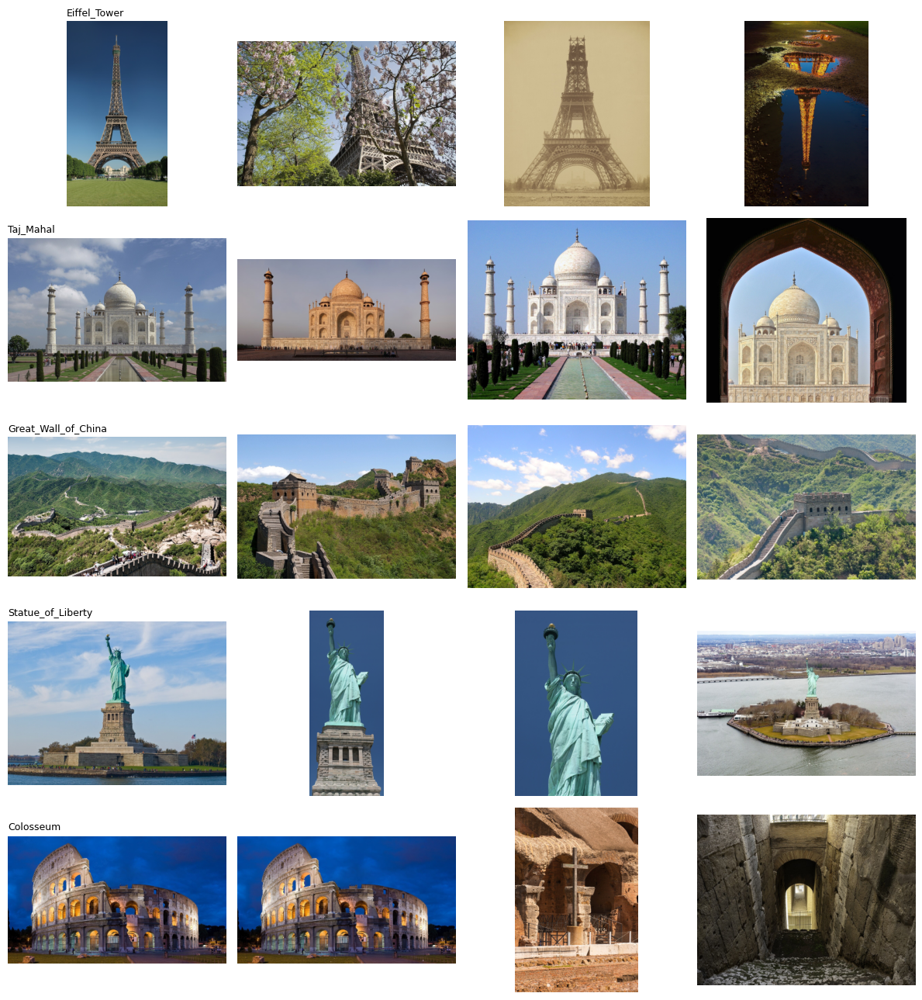

In [ ]:
# montage of the database (up to 4 photos per landmark)
def load_color(path, max_side=MAX_SIDE):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError("cannot read " + path)
    h, w = img.shape[:2]
    s = max_side / max(h, w)
    if s < 1:
        img = cv2.resize(img, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
    return img

rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(len(LANDMARKS), 4, figsize=(12, 2.6 * len(LANDMARKS)))
for i, lm in enumerate(LANDMARKS):
    paths = list_images(os.path.join(DB_DIR, lm))[:4]
    for j in range(4):
        ax = axes[i][j]; ax.axis("off")
        if j < len(paths):
            ax.imshow(rgb(load_color(paths[j], 400)))
        if j == 0:
            ax.set_title(lm, fontsize=9, loc="left")
plt.tight_layout(); plt.savefig("/content/database_montage.png", dpi=120); plt.show()

## Task 2 — SIFT feature extraction on the reference images

Each reference image is loaded, converted to grayscale, and SIFT keypoints + 128-dimensional descriptors are extracted and stored together with the landmark label.

In [ ]:
sift = cv2.SIFT_create(nfeatures=3000)

db = []   # one entry per reference image
for lm in LANDMARKS:
    for path in list_images(os.path.join(DB_DIR, lm)):
        color = load_color(path)
        gray = cv2.cvtColor(color, cv2.COLOR_BGR2GRAY)
        kp, des = sift.detectAndCompute(gray, None)
        if des is None or len(kp) < 10:
            print("skipping (too few keypoints):", path); continue
        db.append({"landmark": lm, "path": path, "color": color, "gray": gray, "kp": kp, "des": des})

db_summary = pd.DataFrame([{"Landmark": e["landmark"], "Image": os.path.basename(e["path"]),
                            "Size": f'{e["gray"].shape[1]}x{e["gray"].shape[0]}', "Keypoints": len(e["kp"]),
                            "Descriptor shape": e["des"].shape} for e in db])
print("Reference images:", len(db), " | total descriptors:", sum(len(e["des"]) for e in db))
db_summary.groupby("Landmark")["Keypoints"].agg(["count", "mean", "min", "max"]).round(0)

Reference images: 40  | total descriptors: 84475


,count,mean,min,max
Landmark,,,,
Colosseum,8,2702.0,2057,3001
Eiffel_Tower,8,1955.0,909,3001
Great_Wall_of_China,8,2962.0,2841,3000
Statue_of_Liberty,8,1118.0,283,2388
Taj_Mahal,8,1822.0,1226,2701


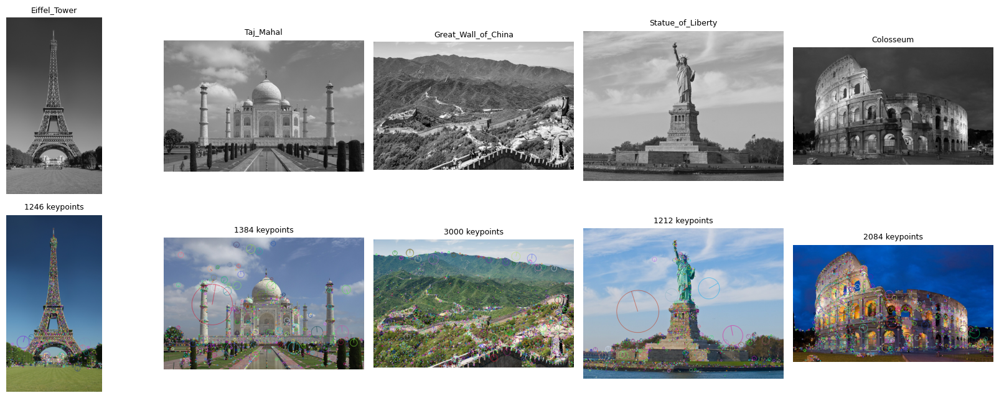

In [ ]:
# reference images with their detected keypoints (rich keypoints show scale and orientation)
fig, axes = plt.subplots(2, len(LANDMARKS), figsize=(3.4 * len(LANDMARKS), 6.5))
for j, lm in enumerate(LANDMARKS):
    e = next(x for x in db if x["landmark"] == lm)
    axes[0][j].imshow(cv2.cvtColor(e["gray"], cv2.COLOR_GRAY2RGB)); axes[0][j].set_title(lm, fontsize=9)
    vis = cv2.drawKeypoints(e["color"], e["kp"], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    axes[1][j].imshow(rgb(vis)); axes[1][j].set_title(f'{len(e["kp"])} keypoints', fontsize=9)
    axes[0][j].axis("off"); axes[1][j].axis("off")
plt.tight_layout(); plt.savefig("/content/reference_keypoints.png", dpi=130); plt.show()

In [ ]:
# store descriptors with their labels (keypoints converted to plain tuples so they can be pickled)
def kp_to_tuple(k):
    return (k.pt, k.size, k.angle, k.response, k.octave, k.class_id)

with open("/content/sift_database.pkl", "wb") as f:
    pickle.dump([{"landmark": e["landmark"], "path": e["path"],
                  "kp": [kp_to_tuple(k) for k in e["kp"]], "des": e["des"]} for e in db], f)
print("Saved /content/sift_database.pkl")

Saved /content/sift_database.pkl


## Task 3 — Query image processing

Loads a query image, converts it to grayscale, detects SIFT keypoints, extracts descriptors and displays the keypoints.

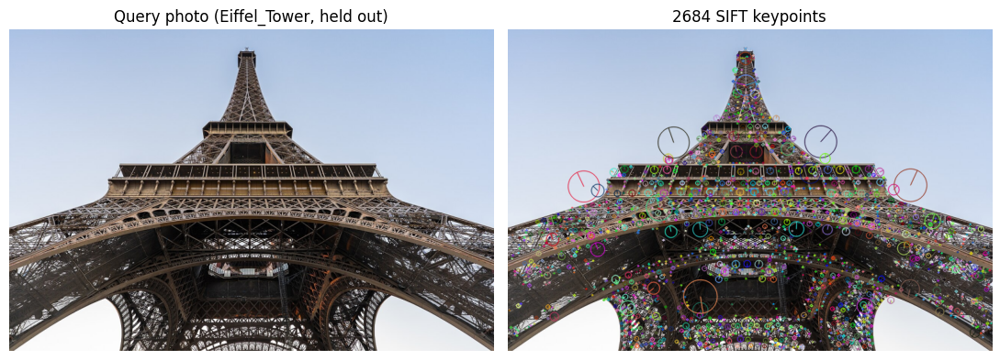

In [ ]:
def process_query(query_bgr, show=True, title="Query image"):
    gray = cv2.cvtColor(query_bgr, cv2.COLOR_BGR2GRAY)
    kp, des = sift.detectAndCompute(gray, None)
    if show:
        vis = cv2.drawKeypoints(query_bgr, kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
        axes[0].imshow(rgb(query_bgr)); axes[0].set_title(title); axes[0].axis("off")
        axes[1].imshow(rgb(vis)); axes[1].set_title(f"{len(kp)} SIFT keypoints"); axes[1].axis("off")
        plt.tight_layout(); plt.show()
    return gray, kp, des

demo_lm = list(LANDMARKS)[0]
demo_path = list_images(os.path.join(QUERY_DIR, demo_lm))[0]
_ = process_query(load_color(demo_path), title=f"Query photo ({demo_lm}, held out)")

## Task 4 — Feature matching and landmark recognition

* Brute-Force matcher, Euclidean (L2) distance, **k-NN with k = 2**
* **Lowe's ratio test** (`RATIO`) removes ambiguous matches
* Reliable matches are counted per landmark; candidates are ranked
* The final decision uses **geometric verification (Task 5) and a rejection threshold**, not only the match count

In [ ]:
bf = cv2.BFMatcher(cv2.NORM_L2)

def ratio_matches(des_q, des_r, ratio=RATIO):
    """kNN (k=2) matching + Lowe's ratio test. queryIdx -> query keypoint, trainIdx -> reference keypoint."""
    if des_q is None or des_r is None or len(des_q) < 2 or len(des_r) < 2:
        return []
    good = []
    for pair in bf.knnMatch(des_q, des_r, k=2):
        if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance:
            good.append(pair[0])
    return good

## Task 5 — Landmark localization (homography + RANSAC)

The reference image corners are projected into the query with the estimated homography. The polygon is only accepted if the transformation is geometrically sensible (finite, convex, non-mirrored, reasonable size); otherwise the system reports that the transformation is unreliable instead of drawing an invalid polygon.

In [ ]:
MIN_H = 8   # minimum matches required to attempt a homography

def validate_polygon(poly, H, q_shape):
    pts = poly.reshape(-1, 2)
    if not np.all(np.isfinite(pts)):
        return False, "projection is not finite"
    if np.linalg.det(H[:2, :2]) <= 0:
        return False, "transformation mirrors or collapses the image"
    if not cv2.isContourConvex(pts.astype(np.float32).reshape(-1, 1, 2)):
        return False, "projected region is not a convex quadrilateral"
    area = cv2.contourArea(pts.astype(np.float32))
    ratio = area / float(q_shape[0] * q_shape[1])
    if ratio < 0.01 or ratio > 10:
        return False, f"projected region has implausible size ({ratio:.3f}x query area)"
    return True, "ok"

def geometric_verify(kp_q, kp_r, good, ref_shape, q_shape):
    out = {"H": None, "mask": None, "inliers": 0, "poly": None, "valid": False, "msg": ""}
    if len(good) < MIN_H:
        out["msg"] = f"too few reliable matches for a homography ({len(good)} < {MIN_H})"
        return out
    src = np.float32([kp_r[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)   # reference points
    dst = np.float32([kp_q[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)   # query points
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_THRESH)
    if H is None or mask is None:
        out["msg"] = "RANSAC could not estimate a homography"
        return out
    out["H"], out["mask"], out["inliers"] = H, mask.ravel().astype(bool), int(mask.sum())
    h, w = ref_shape[:2]
    corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    poly = cv2.perspectiveTransform(corners, H)
    out["valid"], out["msg"] = validate_polygon(poly, H, q_shape)
    if out["valid"]:
        out["poly"] = poly
    return out

### Recognition function (Tasks 4 + 5 combined)

In [ ]:
def recognize(query_bgr):
    t0 = time.perf_counter()
    gray = cv2.cvtColor(query_bgr, cv2.COLOR_BGR2GRAY)
    kp_q, des_q = sift.detectAndCompute(gray, None)

    # 1) ratio-test matches against every reference image, grouped by landmark
    per_lm = {}
    for entry in db:
        per_lm.setdefault(entry["landmark"], []).append((entry, ratio_matches(des_q, entry["des"])))

    candidates = []
    for lm, items in per_lm.items():
        items.sort(key=lambda t: len(t[1]), reverse=True)
        candidates.append({"landmark": lm, "items": items, "good_matches": len(items[0][1]),
                           "total_good": sum(len(g) for _, g in items), "inliers": 0, "geo": None})
    candidates.sort(key=lambda c: c["good_matches"], reverse=True)

    # 2) geometric verification (RANSAC) for the top-K candidates, best 2 reference images each
    for c in candidates[:TOP_K]:
        best = None
        for entry, good in c["items"][:2]:
            geo = geometric_verify(kp_q, entry["kp"], good, entry["gray"].shape, gray.shape)
            geo.update({"entry": entry, "good": good})
            if best is None or geo["inliers"] > best["inliers"]:
                best = geo
        c["geo"], c["inliers"], c["good_matches"] = best, best["inliers"], len(best["good"])

    ranking = sorted(candidates, key=lambda c: (c["inliers"], c["good_matches"]), reverse=True)
    top = ranking[0]
    runner = ranking[1] if len(ranking) > 1 else None
    geo = top["geo"]

    # 3) rejection rules
    reasons = []
    if top["good_matches"] < MIN_GOOD:
        reasons.append(f"only {top['good_matches']} reliable matches (need >= {MIN_GOOD})")
    if geo is None or not geo["valid"]:
        reasons.append("geometric verification failed: " + (geo["msg"] if geo else "not verified"))
    else:
        if top["inliers"] < MIN_INLIERS:
            reasons.append(f"only {top['inliers']} RANSAC inliers (need >= {MIN_INLIERS})")
        if top["good_matches"] and top["inliers"] / top["good_matches"] < MIN_INLIER_RATIO:
            reasons.append(f"inlier ratio {top['inliers'] / top['good_matches']:.2f} below {MIN_INLIER_RATIO}")
    if runner is not None and runner["inliers"] > 0 and top["inliers"] < MARGIN * runner["inliers"]:
        reasons.append(f"ambiguous: runner-up {runner['landmark']} has {runner['inliers']} inliers")
    recognized = len(reasons) == 0

    return {"kp_q": kp_q, "n_kp": len(kp_q), "ranking": ranking, "top": top, "recognized": recognized,
            "reasons": reasons, "predicted": top["landmark"] if recognized else "Unknown (rejected)",
            "best_candidate": top["landmark"], "time_s": time.perf_counter() - t0}

def ranking_table(res):
    return pd.DataFrame([{"Rank": i + 1, "Landmark": c["landmark"], "Reliable matches (best ref)": c["good_matches"],
                          "Reliable matches (all refs)": c["total_good"], "RANSAC inliers": c["inliers"]}
                         for i, c in enumerate(res["ranking"])])

### Display function — all expected outputs (query, keypoints, matches, prediction, localization, decision)

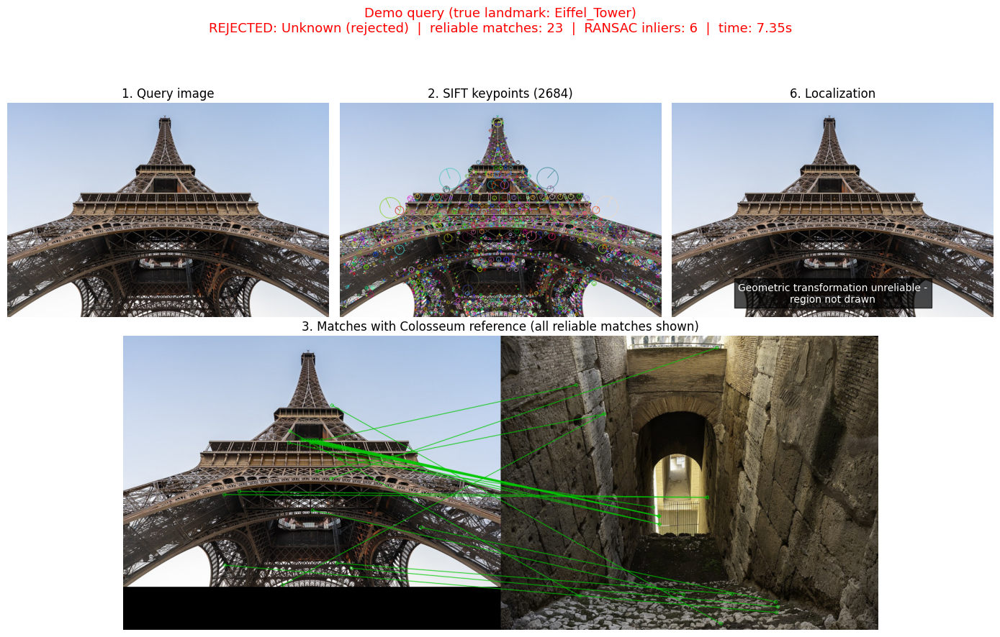

PREDICTED LANDMARK : none (best candidate: Colosseum)
RELIABLE MATCHES   : 23    RANSAC INLIERS: 6
DECISION           : Image REJECTED - geometric verification failed: projected region is not a convex quadrilateral; ambiguous: runner-up Statue_of_Liberty has 6 inliers



,Rank,Landmark,Reliable matches (best ref),Reliable matches (all refs),RANSAC inliers
0,1,Colosseum,23,117,6
1,2,Statue_of_Liberty,20,132,6
2,3,Eiffel_Tower,26,118,5
3,4,Taj_Mahal,18,93,0
4,5,Great_Wall_of_China,18,81,0


In [ ]:
def show_result(query_bgr, res, title="", save_as=None):
    top, geo = res["top"], res["top"]["geo"]
    if geo is not None:
        entry, good = geo["entry"], geo["good"]
    else:
        entry, good = top["items"][0]
    use_mask = geo is not None and geo["valid"] and geo["mask"] is not None

    kp_vis = cv2.drawKeypoints(query_bgr, res["kp_q"], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    match_vis = cv2.drawMatches(query_bgr, res["kp_q"], entry["color"], entry["kp"], good, None,
                                matchColor=(0, 200, 0), singlePointColor=None,
                                matchesMask=geo["mask"].astype(int).tolist() if use_mask else None,
                                flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    loc = query_bgr.copy()
    localized = res["recognized"] and geo is not None and geo["valid"] and geo["poly"] is not None
    if localized:
        cv2.polylines(loc, [np.int32(geo["poly"])], True, (0, 0, 255), 4)

    status = "RECOGNIZED" if res["recognized"] else "REJECTED"
    fig = plt.figure(figsize=(14, 9))
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.15])
    ax = fig.add_subplot(gs[0, 0]); ax.imshow(rgb(query_bgr)); ax.set_title("1. Query image"); ax.axis("off")
    ax = fig.add_subplot(gs[0, 1]); ax.imshow(rgb(kp_vis)); ax.set_title(f"2. SIFT keypoints ({res['n_kp']})"); ax.axis("off")
    ax = fig.add_subplot(gs[0, 2]); ax.imshow(rgb(loc)); ax.axis("off")
    ax.set_title("6. Localized landmark region" if localized else "6. Localization")
    if not localized:
        ax.text(0.5, 0.06, "Geometric transformation unreliable -\nregion not drawn", transform=ax.transAxes,
                ha="center", va="bottom", color="white", fontsize=10, bbox=dict(facecolor="black", alpha=0.7))
    ax = fig.add_subplot(gs[1, :]); ax.imshow(rgb(match_vis)); ax.axis("off")
    ax.set_title(f"3. Matches with {entry['landmark']} reference "
                 f"({'RANSAC inliers shown' if use_mask else 'all reliable matches shown'})")
    color = "green" if res["recognized"] else "red"
    fig.suptitle(f"{title}\n{status}: {res['predicted']}  |  reliable matches: {top['good_matches']}  |  "
                 f"RANSAC inliers: {top['inliers']}  |  time: {res['time_s']:.2f}s", color=color, fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    if save_as:
        os.makedirs(os.path.dirname(save_as), exist_ok=True)
        plt.savefig(save_as, dpi=110)
    plt.show()

    print("PREDICTED LANDMARK :", res["predicted"] if res["recognized"] else f"none (best candidate: {res['best_candidate']})")
    print("RELIABLE MATCHES   :", top["good_matches"], "   RANSAC INLIERS:", top["inliers"])
    print("DECISION           :", "Landmark RECOGNIZED" if res["recognized"] else "Image REJECTED - " + "; ".join(res["reasons"]))
    print()
    display(ranking_table(res))

q = load_color(demo_path)
show_result(q, recognize(q), title=f"Demo query (true landmark: {demo_lm})")

## Task 6 — Performance evaluation

For each landmark, a **held-out photo** is tested as: original, rotated (30°), resized (50%), reduced brightness (35% of original), plus a **different held-out photo of the same landmark** (different viewpoint). Photos of landmarks **not in the database** test the rejection rule. Predicted landmark, keypoints, reliable matches, decision and processing time are recorded.

In [ ]:
def rotate_bound(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += nw / 2 - w / 2; M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(img, M, (nw, nh), borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

def resize_by(img, f):
    return cv2.resize(img, None, fx=f, fy=f, interpolation=cv2.INTER_AREA)

def darken(img, factor=0.35):
    return np.clip(img.astype(np.float32) * factor, 0, 255).astype(np.uint8)

def build_tests():
    tests = []
    for lm in LANDMARKS:
        qf = list_images(os.path.join(QUERY_DIR, lm))
        base = load_color(qf[0])
        tests += [(lm, "Original", base),
                  (lm, "Rotated (30 deg)", rotate_bound(base, 30)),
                  (lm, "Resized (50%)", resize_by(base, 0.5)),
                  (lm, "Reduced brightness", darken(base))]
        if len(qf) > 1:
            tests.append((lm, "Different viewpoint", load_color(qf[1])))
    for f in list_images(os.path.join(QUERY_DIR, "_unknown")):
        tests.append(("Unknown", "Unknown landmark", load_color(f)))
    return tests

tests = build_tests()
print("Number of test queries:", len(tests))

Number of test queries: 29


In [ ]:
rows = []
for true_lm, cond, img in tests:
    res = recognize(img)
    if true_lm == "Unknown":
        correct = not res["recognized"]
    else:
        correct = res["recognized"] and res["predicted"] == true_lm
    rows.append({"True landmark": true_lm, "Test condition": cond,
                 "Predicted landmark": res["predicted"], "Best candidate": res["best_candidate"],
                 "Keypoints (query)": res["n_kp"], "Reliable matches": res["top"]["good_matches"],
                 "RANSAC inliers": res["top"]["inliers"],
                 "Decision": "Recognized" if res["recognized"] else "Rejected",
                 "Correct": "Yes" if correct else "No", "Time (s)": round(res["time_s"], 2)})

results_df = pd.DataFrame(rows)
results_df.to_csv("/content/sift_results.csv", index=False)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 20)
results_df

In [16]:
# summary by test condition + overall figures
summary = results_df.assign(ok=results_df["Correct"].eq("Yes")).groupby("Test condition").agg(
    Tests=("ok", "size"), Correct=("ok", "sum"), Mean_inliers=("RANSAC inliers", "mean"),
    Mean_time_s=("Time (s)", "mean")).round(2)
summary["Accuracy %"] = (summary["Correct"] / summary["Tests"] * 100).round(1)
print(summary.to_string())

known = results_df[results_df["True landmark"] != "Unknown"]
unk = results_df[results_df["True landmark"] == "Unknown"]
print(f"\nKnown-landmark queries correctly recognized: {(known['Correct'] == 'Yes').sum()} / {len(known)}")
print(f"Unknown-landmark queries correctly rejected: {(unk['Correct'] == 'Yes').sum()} / {len(unk)}")
print(f"False accepts (unknown or wrong landmark accepted): "
      f"{((results_df['Decision'] == 'Recognized') & (results_df['Correct'] == 'No')).sum()}")
print(f"Average processing time: {results_df['Time (s)'].mean():.2f} s per query")

                     Tests  Correct  Mean_inliers  Mean_time_s  Accuracy %
Test condition                                                            
Different viewpoint      5        2        234.00         6.17        40.0
Original                 5        2        243.60         7.31        40.0
Reduced brightness       5        2         38.60         2.45        40.0
Resized (50%)            5        1         79.60         2.40        20.0
Rotated (30 deg)         5        2        187.20         8.47        40.0
Unknown landmark         4        4          5.25         3.06       100.0

Known-landmark queries correctly recognized: 9 / 25
Unknown-landmark queries correctly rejected: 4 / 4
False accepts (unknown or wrong landmark accepted): 0
Average processing time: 5.04 s per query


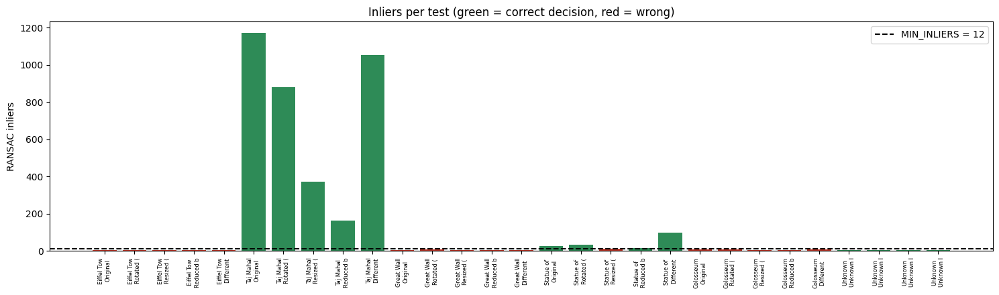

In [17]:
# RANSAC inliers of every test against the acceptance threshold
colors = results_df["Correct"].map({"Yes": "#2e8b57", "No": "#c0392b"})
labels = results_df["True landmark"].str.replace("_", " ").str[:10] + "\n" + results_df["Test condition"].str[:9]
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.bar(range(len(results_df)), results_df["RANSAC inliers"], color=colors)
ax.axhline(MIN_INLIERS, color="k", linestyle="--", label=f"MIN_INLIERS = {MIN_INLIERS}")
ax.set_xticks(range(len(results_df))); ax.set_xticklabels(labels, rotation=90, fontsize=6)
ax.set_ylabel("RANSAC inliers"); ax.set_title("Inliers per test (green = correct decision, red = wrong)")
ax.legend(); plt.tight_layout(); plt.savefig("/content/inliers_per_test.png", dpi=130); plt.show()

### Screenshots of application output

Runs the full application display for one landmark under every condition, plus an unknown landmark. Figures are saved in `/content/screenshots`. Change `DEMO_LANDMARK` to capture others.

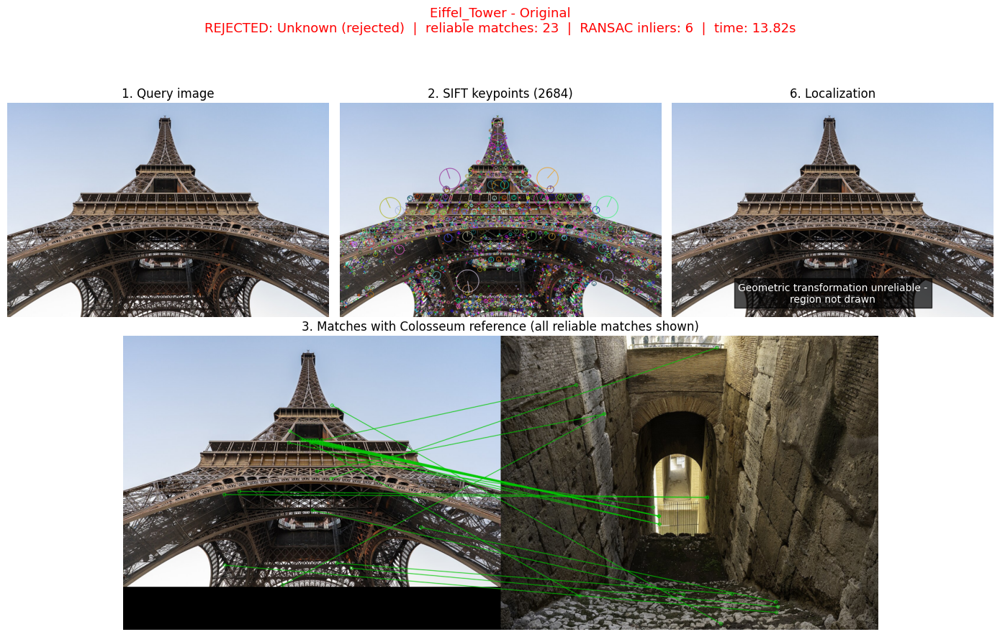

PREDICTED LANDMARK : none (best candidate: Colosseum)
RELIABLE MATCHES   : 23    RANSAC INLIERS: 6
DECISION           : Image REJECTED - geometric verification failed: projected region is not a convex quadrilateral; ambiguous: runner-up Statue_of_Liberty has 6 inliers



,Rank,Landmark,Reliable matches (best ref),Reliable matches (all refs),RANSAC inliers
0,1,Colosseum,23,117,6
1,2,Statue_of_Liberty,20,132,6
2,3,Eiffel_Tower,26,118,5
3,4,Taj_Mahal,18,93,0
4,5,Great_Wall_of_China,18,81,0


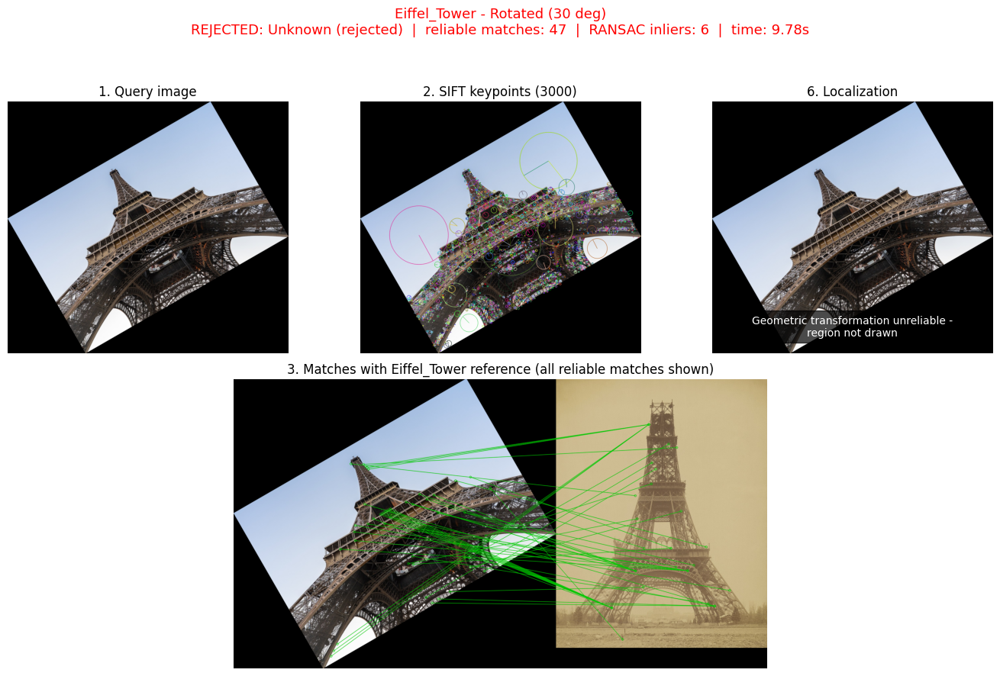

PREDICTED LANDMARK : none (best candidate: Eiffel_Tower)
RELIABLE MATCHES   : 47    RANSAC INLIERS: 6
DECISION           : Image REJECTED - geometric verification failed: projected region is not a convex quadrilateral; ambiguous: runner-up Great_Wall_of_China has 6 inliers



,Rank,Landmark,Reliable matches (best ref),Reliable matches (all refs),RANSAC inliers
0,1,Eiffel_Tower,47,155,6
1,2,Great_Wall_of_China,25,112,6
2,3,Colosseum,24,152,6
3,4,Statue_of_Liberty,23,145,0
4,5,Taj_Mahal,22,136,0


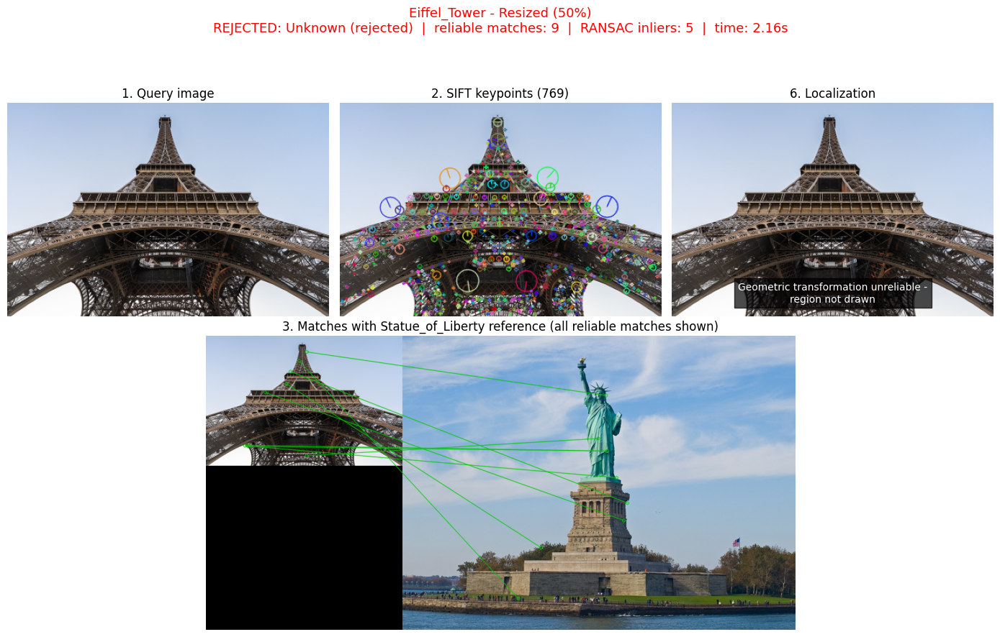

PREDICTED LANDMARK : none (best candidate: Statue_of_Liberty)
RELIABLE MATCHES   : 9    RANSAC INLIERS: 5
DECISION           : Image REJECTED - only 9 reliable matches (need >= 15); geometric verification failed: transformation mirrors or collapses the image; ambiguous: runner-up Colosseum has 4 inliers



,Rank,Landmark,Reliable matches (best ref),Reliable matches (all refs),RANSAC inliers
0,1,Statue_of_Liberty,9,49,5
1,2,Colosseum,9,38,4
2,3,Eiffel_Tower,7,35,0
3,4,Taj_Mahal,6,30,0
4,5,Great_Wall_of_China,5,22,0


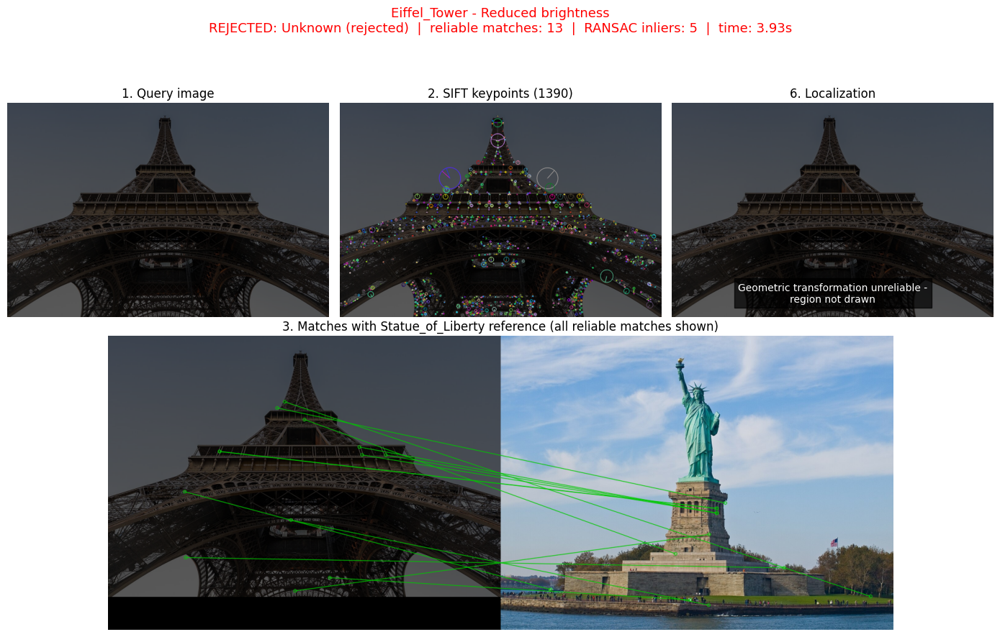

PREDICTED LANDMARK : none (best candidate: Statue_of_Liberty)
RELIABLE MATCHES   : 13    RANSAC INLIERS: 5
DECISION           : Image REJECTED - only 13 reliable matches (need >= 15); geometric verification failed: projected region is not a convex quadrilateral; ambiguous: runner-up Eiffel_Tower has 5 inliers



,Rank,Landmark,Reliable matches (best ref),Reliable matches (all refs),RANSAC inliers
0,1,Statue_of_Liberty,13,64,5
1,2,Eiffel_Tower,12,64,5
2,3,Colosseum,12,45,4
3,4,Taj_Mahal,10,41,0
4,5,Great_Wall_of_China,6,32,0


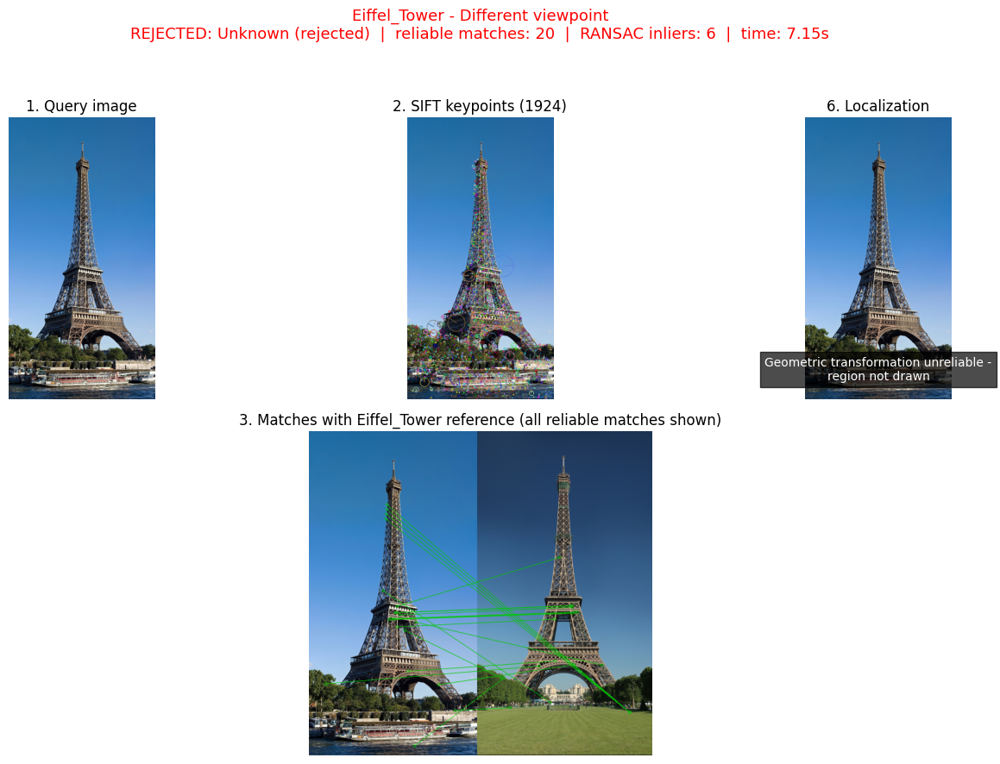

PREDICTED LANDMARK : none (best candidate: Eiffel_Tower)
RELIABLE MATCHES   : 20    RANSAC INLIERS: 6
DECISION           : Image REJECTED - geometric verification failed: transformation mirrors or collapses the image; ambiguous: runner-up Statue_of_Liberty has 6 inliers



,Rank,Landmark,Reliable matches (best ref),Reliable matches (all refs),RANSAC inliers
0,1,Eiffel_Tower,20,94,6
1,2,Statue_of_Liberty,17,103,6
2,3,Colosseum,16,82,5
3,4,Taj_Mahal,12,73,0
4,5,Great_Wall_of_China,12,70,0


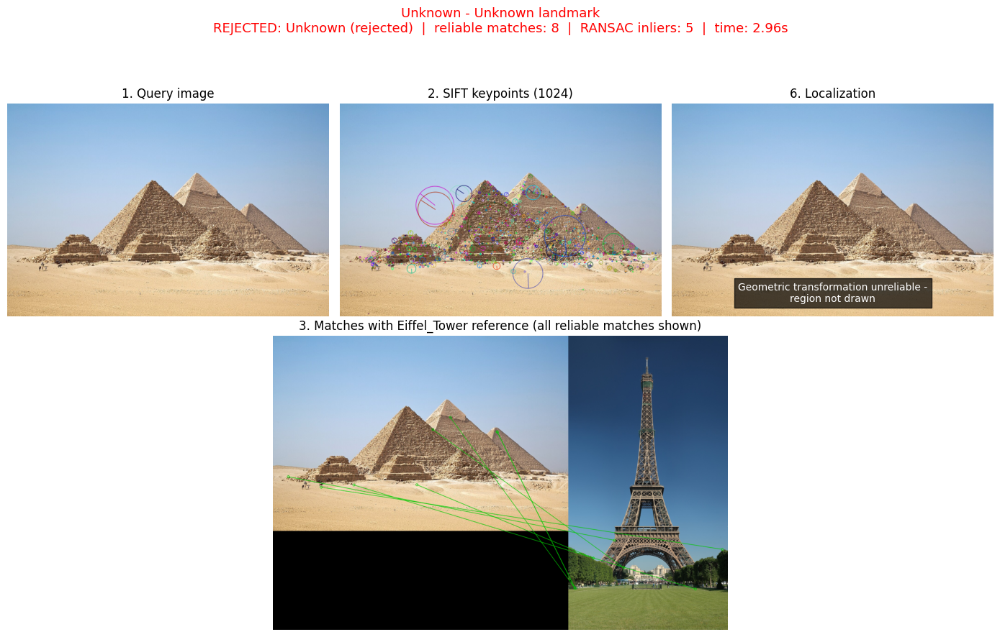

PREDICTED LANDMARK : none (best candidate: Eiffel_Tower)
RELIABLE MATCHES   : 8    RANSAC INLIERS: 5
DECISION           : Image REJECTED - only 8 reliable matches (need >= 15); geometric verification failed: transformation mirrors or collapses the image; ambiguous: runner-up Statue_of_Liberty has 4 inliers



,Rank,Landmark,Reliable matches (best ref),Reliable matches (all refs),RANSAC inliers
0,1,Eiffel_Tower,8,35,5
1,2,Statue_of_Liberty,12,50,4
2,3,Colosseum,11,40,4
3,4,Great_Wall_of_China,8,35,0
4,5,Taj_Mahal,7,32,0


In [18]:
DEMO_LANDMARK = list(LANDMARKS)[0]
shutil.rmtree("/content/screenshots", ignore_errors=True)

demo_tests = [t for t in tests if t[0] == DEMO_LANDMARK] + [t for t in tests if t[0] == "Unknown"][:1]
for true_lm, cond, img in demo_tests:
    res = recognize(img)
    fname = re.sub(r"[^A-Za-z0-9]+", "_", f"{true_lm}_{cond}") + ".png"
    show_result(img, res, title=f"{true_lm} - {cond}", save_as="/content/screenshots/" + fname)

## Try your own photo (optional)

In [19]:
from google.colab import files as colab_files

up = colab_files.upload()
for name in up:
    q = load_color(name)
    show_result(q, recognize(q), title=f"Uploaded query: {name}")

## Export deliverables

In [20]:
with pd.ExcelWriter("/content/sift_results.xlsx") as writer:
    results_df.to_excel(writer, sheet_name="Experimental_Results", index=False)
    summary.to_excel(writer, sheet_name="Summary_by_Condition")
    db_summary.drop(columns=["Descriptor shape"]).to_excel(writer, sheet_name="Database", index=False)

shutil.make_archive("/content/landmark_db", "zip", DB_DIR)
if os.path.isdir("/content/screenshots"):
    shutil.make_archive("/content/screenshots", "zip", "/content/screenshots")

from google.colab import files as colab_files
for f in ["sift_results.xlsx", "landmark_db.zip", "screenshots.zip", "sift_database.pkl"]:
    if os.path.exists("/content/" + f):
        colab_files.download("/content/" + f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Discussion — performance and limitations

**How SIFT supports recognition.** SIFT keypoints are detected in scale space and described relative to a dominant orientation, so the descriptors stay similar under changes of scale and in-plane rotation, and the gradient-based description with normalization tolerates moderate brightness changes. This is why the rotated, resized and darkened versions of a photo are normally still recognized. Combining the ratio test with RANSAC homography verification means a landmark is accepted only when many matches agree on one consistent geometric transformation, which is what separates a true match from a coincidental pile of weak matches and lets the system reject photos of landmarks that are not in the database.

**Reading your results.** Use the results table and the inlier chart to state: which conditions were recognized reliably, which test (typically *Different viewpoint*) gave the lowest inlier counts, whether any unknown image was wrongly accepted, and the average processing time per query. If a wrong decision occurs, compare its inliers with `MIN_INLIERS` / `MARGIN` and explain whether the threshold was too loose or too strict.

**Limitations.**
* Strong viewpoint changes (large perspective change, different side of the building) reduce the number of repeatable keypoints and break the planar-homography assumption, because a 3-D landmark is not a flat plane.
* Landmarks with repeated structures (Colosseum arches, Great Wall segments, tower lattices) produce many look-alike descriptors and ambiguous matches.
* Low-texture, heavily blurred, very small or strongly night-time images yield few keypoints.
* Occlusion, crowds, scaffolding, seasons and weather alter appearance; SIFT is not fully illumination invariant.
* Query time grows linearly with database size because every reference descriptor set is searched; a large system needs approximate nearest-neighbour search (FLANN), a visual vocabulary (bag of words) or a learned global descriptor for a first-stage shortlist.
* Thresholds (`RATIO`, `MIN_GOOD`, `MIN_INLIERS`, `MARGIN`) were set by hand on a small test set; they need tuning on more data.
* A small database with few images per landmark limits coverage of viewpoints; adding more varied reference photos is the most direct improvement.